In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder
from sklearn.metrics import precision_score, recall_score, f1_score, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df_train= pd.read_csv("/kaggle/input/datasets/zakariaboutakka/morocco-crop-dataset/train.csv")
df_test= pd.read_csv("/kaggle/input/datasets/zakariaboutakka/morocco-crop-dataset/test.csv")
df_val= pd.read_csv("/kaggle/input/datasets/zakariaboutakka/morocco-crop-dataset/validation.csv")

In [3]:
df_train

,sample_id,B1,B2,B3,B4,B5,B6,B7,B8,B8A,B9,B11,B12,NDVI,target
0,r2_628897512b6a2af8,735.567992,740.099161,1103.821592,1412.509516,1901.466817,2597.579302,2857.496966,3022.922050,3160.550781,3262.820296,3684.901528,2887.059773,0.362266,wheat
1,r2_52d40a7666662fbd,752.931868,812.251386,1172.340007,1598.965384,2033.616183,2468.844736,2697.697668,2880.773913,3044.599874,3124.898557,3869.040977,3079.286981,0.286029,wheat
2,r2_e76f16082a693985,819.912019,975.489611,1365.777977,1904.760633,2320.778855,2671.421702,2907.777672,3130.940754,3283.921426,3339.404644,4396.221336,3628.698620,0.244120,wheat
3,r2_3839538f981ce331,1001.256331,1198.507762,1684.384185,2361.372939,2784.518664,3070.120886,3279.390119,3499.690057,3605.214034,3556.593666,4756.978472,3886.156420,0.195382,wheat
4,r2_f7cf7a2cbbff3f42,894.788026,737.549029,1095.658738,1346.803236,1833.658738,2538.135761,2808.466181,2910.387379,3107.418447,3350.548867,3945.857443,3290.001780,0.371730,maize
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
909,r2_341c26527f18c802,740.863851,788.962869,1136.895522,1347.436840,1833.563160,2799.997634,3090.405169,3171.850746,3335.351292,3860.472333,2980.575355,2289.661631,0.404743,wheat
910,r2_31133c5b5dce06ca,714.503923,732.895864,1040.470463,1428.220491,1803.756137,2195.689889,2397.183500,2554.378881,2707.087322,2922.119493,3302.555207,2591.558065,0.283086,wheat
911,r2_6f44ccce3c322670,811.581183,531.102151,971.238844,820.933737,1685.238172,3876.555376,4335.569220,4646.061290,4560.913306,3948.227957,3006.725538,1957.063575,0.698091,alfalfa
912,r2_2e566d399eb4242b,691.955806,604.256091,963.053941,1086.083347,1625.690472,2634.644261,2987.471517,3149.651487,3332.592169,3522.964040,2782.952613,1970.563267,0.490854,wheat


In [4]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 914 entries, 0 to 913
Data columns (total 15 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   sample_id  914 non-null    object 
 1   B1         914 non-null    float64
 2   B2         914 non-null    float64
 3   B3         914 non-null    float64
 4   B4         914 non-null    float64
 5   B5         914 non-null    float64
 6   B6         914 non-null    float64
 7   B7         914 non-null    float64
 8   B8         914 non-null    float64
 9   B8A        914 non-null    float64
 10  B9         914 non-null    float64
 11  B11        914 non-null    float64
 12  B12        914 non-null    float64
 13  NDVI       914 non-null    float64
 14  target     914 non-null    object 
dtypes: float64(13), object(2)
memory usage: 107.2+ KB


In [5]:
df_train.describe()

,B1,B2,B3,B4,B5,B6,B7,B8,B8A,B9,B11,B12,NDVI
count,914.000000,914.000000,914.000000,914.000000,914.000000,914.000000,914.000000,914.000000,914.000000,914.000000,914.000000,914.000000,914.000000
mean,724.602978,765.024342,1080.519307,1309.674616,1787.972449,2657.614845,2969.830246,3164.291911,3271.462008,3311.769682,3194.277218,2346.057529,0.399936
std,442.574491,467.771476,459.256468,590.215200,577.360668,841.381910,982.261043,1041.631446,1002.194699,960.021292,768.301595,845.404473,0.186436
min,163.651798,114.434772,152.293584,121.702337,204.284964,254.421420,289.542959,310.531086,334.595406,387.504645,403.149069,264.151089,0.050905
25%,569.136845,584.838142,881.470435,940.718982,1444.694603,2130.786723,2338.708566,2465.274889,2615.790948,2745.394650,2810.106921,1818.794245,0.268579
50%,656.822568,736.268744,1045.817299,1313.457818,1756.060715,2592.414491,2869.311349,3081.867065,3236.415031,3323.149425,3116.003152,2159.766057,0.320749
75%,788.560258,848.456918,1189.268053,1617.013014,2074.876490,3166.538892,3572.058894,3799.885919,3898.627396,3904.292048,3523.523442,2816.859062,0.515869
max,5709.965409,6294.211246,6163.090339,6234.293943,6561.704046,6538.004103,6468.502051,6895.525380,6651.823331,9478.866175,6899.265565,5978.137917,0.886649


In [6]:
df_train.isnull().sum()

sample_id    0
B1           0
B2           0
B3           0
B4           0
B5           0
B6           0
B7           0
B8           0
B8A          0
B9           0
B11          0
B12          0
NDVI         0
target       0
dtype: int64

In [7]:
#Find Identical columns
def identicalcols(df):
    identical_cols = []
    cols = df.columns
    for i in range(len(cols)):
        for j in range(i + 1, len(cols)):
            if df[cols[i]].equals(df[cols[j]]):
                identical_cols.append((cols[i], cols[j]))
    return identical_cols

duplicates = identicalcols(df_train)

if duplicates:
    print("Identical columns:")
    for pair in duplicates:
        print(f"{pair[0]} == {pair[1]}")
else:
    print("No identical columns.")

No identical columns.


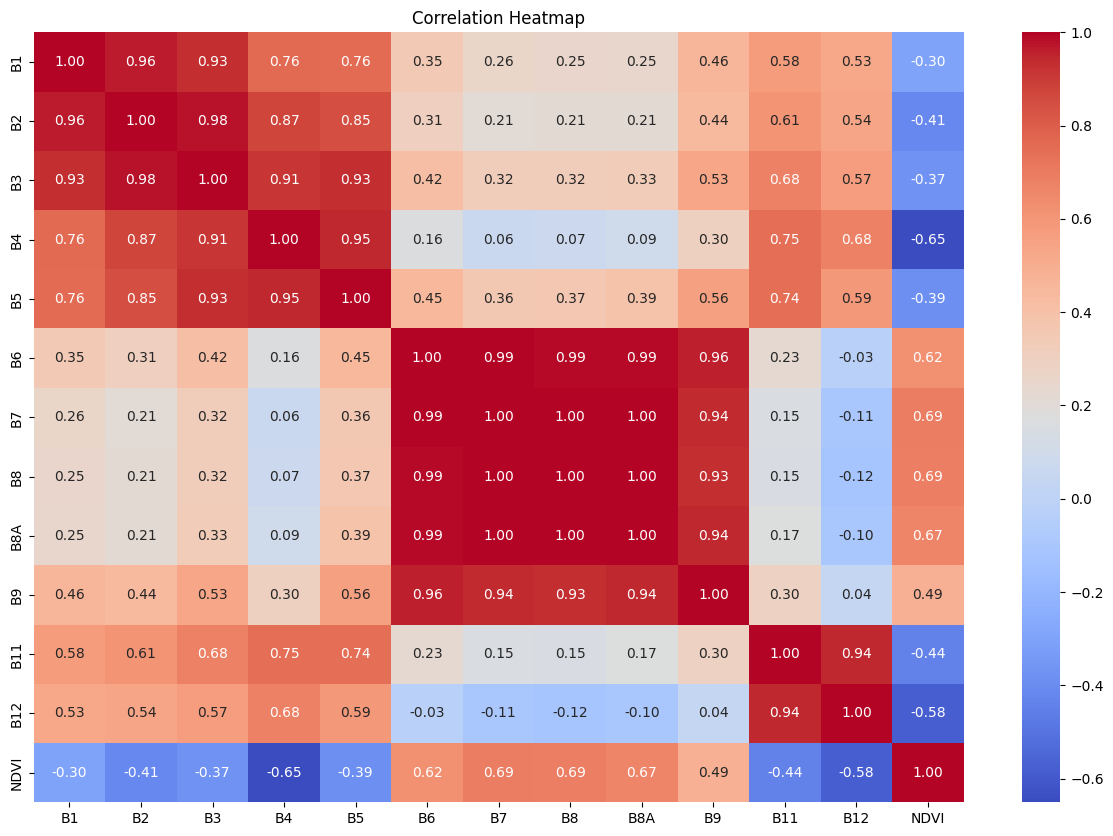

In [8]:
numeric_df = df_train.select_dtypes(include=['number'])
correlated_data = numeric_df.corr()
plt.figure(figsize=(15, 10))
sns.heatmap(correlated_data, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

# **Quantum**

In [9]:
!pip install qiskit
!pip install qiskit-aer
!pip uninstall -y qiskit qiskit-machine-learning
!pip install qiskit==0.43.2 qiskit-machine-learning==0.9.1

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 34.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 52.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [qiskit]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.2/14.2 MB 10.2 MB/s  0:00:01
Found existing installation: qiskit 2.6.2
Uninstalling qiskit-2.6.2:
  Successfully uninstalled qiskit-2.6.2
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.0/5.0 MB 10.3 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
INFO: pip is looking at multiple versions of qiskit to determine which version is compatible with other requirements. This could take a while.
ERROR: Could not find a version that satisfies the requirement qiskit-aer==0.12.1 (from qiskit) (from versions: 0.1.0, 0.

In [10]:
!pip install qiskit qiskit-machine-learning qiskit_algorithms qiskit-aer

  Using cached qiskit-2.6.2-cp310-abi3-manylinux_2_28_x86_64.whl.metadata (14 kB)
  Using cached qiskit_machine_learning-0.9.1-py3-none-any.whl.metadata (13 kB)
Using cached qiskit-2.6.2-cp310-abi3-manylinux_2_28_x86_64.whl (9.5 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [qiskit_algorithms]


In [11]:
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score
from qiskit.circuit.library import ZZFeatureMap, ZFeatureMap, RealAmplitudes, EfficientSU2
from qiskit_machine_learning.algorithms import VQC
from qiskit_algorithms.optimizers import COBYLA, SPSA,ADAM
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error
from qiskit_aer.primitives import Sampler
import matplotlib.pyplot as plt
from IPython.display import clear_output

In [12]:
def callback_graph(*args):
    clear_output(wait=True)

    # Determine the objective value based on optimizer callback signature
    if len(args) == 2:
        obj_func_eval = args[1]
    elif len(args) >= 3:
        obj_func_eval = args[2]
    else:
        obj_func_eval = args[0] if len(args) > 0 else 0

    objective_func_vals.append(obj_func_eval)
    plt.title("Objective function value against Iteration")
    plt.xlabel("Iteration")
    plt.ylabel("Objective function value")
    plt.plot(range(len(objective_func_vals)), objective_func_vals)
    plt.show()

In [13]:
df_train = pd.read_csv("/kaggle/input/datasets/zakariaboutakka/morocco-crop-dataset/train.csv")

# Define the feature columns present in the dataset (excluding identifier and target)
feature_columns = ['B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B9', 'B11', 'B12', 'NDVI']

X_train = df_train[feature_columns].to_numpy(dtype=float)
X_test = df_test[feature_columns].to_numpy(dtype=float)
X_val = df_val[feature_columns].to_numpy(dtype=float)

# Target: Use the categorical crop type column for classification
label_encoder = LabelEncoder()
y_train = label_encoder.fit_transform(df_train['target'].values)
y_val = label_encoder.transform(df_val['target'].values)
# Removed test set target encoding since df_test doesn't have a 'target' column

# Preprocessing features
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

In [14]:
##function to Train vqc with different configurations
def train_vqc(num_qubits, feature_map_type, ansatz_type, reps, optimizer_type, add_noise=False):
    #dimensionality reduction to num_qubits
    pca = PCA(n_components=2*num_qubits)
    X_train_pca = pca.fit_transform(X_train_scaled)
    X_val_pca = pca.transform(X_val_scaled)

    #feature map
    if feature_map_type == 'ZZ':
        feature_map = ZZFeatureMap(feature_dimension=num_qubits, reps=2, entanglement='linear')
    elif feature_map_type == 'Z':
        feature_map = ZFeatureMap(feature_dimension=num_qubits, reps=2)

    #ansatz
    if ansatz_type == 'RealAmplitudes':
        ansatz = RealAmplitudes(num_qubits=num_qubits, reps=reps)
    elif ansatz_type == 'EfficientSU2':
        ansatz = EfficientSU2(num_qubits=num_qubits, reps=reps)
    elif optimizer_type == 'Adam':
         from qiskit.algorithms.optimizers import ADAM
         optimizer = ADAM(maxiter=100, lr=0.1)
    #optimizer
    if optimizer_type == 'COBYLA':
        optimizer = COBYLA(maxiter=100)
    elif optimizer_type == 'SPSA':
        optimizer = SPSA(maxiter=100)


    if add_noise:
        noise_model = NoiseModel()
        dep_error = depolarizing_error(0.01, 1)
        noise_model.add_all_qubit_quantum_error(dep_error, ['rx', 'ry', 'rz'])
        sampler = Sampler(options={"noise_model": noise_model})
    else:
        sampler = Sampler()

    # VQC
    global objective_func_vals
    objective_func_vals = []
    vqc = VQC(
        feature_map=feature_map,
        ansatz=ansatz,
        optimizer=optimizer,
        sampler=sampler,
        callback=callback_graph
    )

    vqc.fit(X_train_pca, y_train)
    y_pred = vqc.predict(X_val_pca)
    acc = accuracy_score(y_val, y_pred)

    qc = feature_map.compose(ansatz).decompose()
    num_params = ansatz.num_parameters
    depth = qc.depth()
    qubits = qc.num_qubits

    print(f"Config: Qubits={num_qubits}, FM={feature_map_type}, Ansatz={ansatz_type}, Reps={reps}, Opt={optimizer_type}, Noise={add_noise}")
    print(f"Accuracy: {acc:.4f}")
    print(f"Parameters: {num_params}, Depth: {depth}, Qubits: {qubits}")

    return vqc, acc, num_params, depth, qubits, pca

In [15]:
configs = [
     (4, 'ZZ', 'RealAmplitudes', 6, 'COBYLA', False),
     (4, 'ZZ', 'RealAmplitudes', 6, 'ADAM', False),
     (4, 'ZZ', 'RealAmplitudes', 6, 'SPSA', False),
     (4, 'Z', 'RealAmplitudes', 6, 'COBYLA', False),
     (4, 'Z', 'RealAmplitudes', 6, 'ADAM', False),
     (4, 'Z', 'RealAmplitudes', 6, 'SPSA', False),
    (4, 'ZZ', 'EfficientSU2', 6, 'COBYLA', False),
     (4, 'ZZ', 'EfficientSU2', 6, 'ADAM', False),
     (4, 'ZZ', 'EfficientSU2', 6, 'SPSA', False),
     (4, 'Z', 'EfficientSU2', 6, 'COBYLA', False),
     (4, 'Z', 'EfficientSU2', 6, 'ADAM', False),
    (4, 'Z', 'EfficientSU2', 6, 'SPSA', False),


]

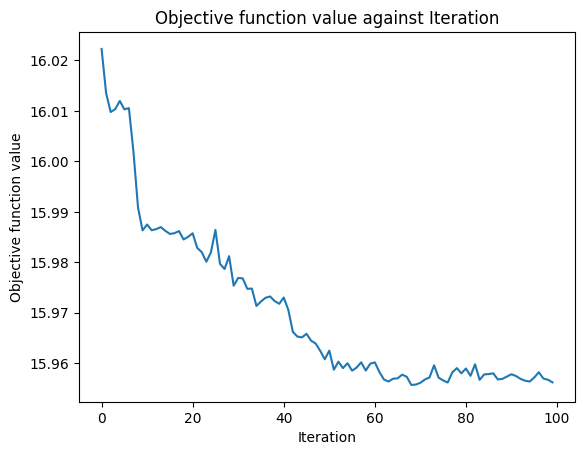

Config: Qubits=4, FM=Z, Ansatz=EfficientSU2, Reps=6, Opt=SPSA, Noise=False
Accuracy: 0.3933
Precision: 0.1733, Recall: 0.3162, F1: 0.2191

Best Model Accuracy: 0.3933
Best Model F1-score: 0.2191
Best Model Precision: 0.1733
Best Metrics: Parameters=56, Depth=1, Qubits=4


In [16]:
import warnings
warnings.filterwarnings('ignore', category=DeprecationWarning)

try:
    from qiskit.primitives import StatevectorSampler as Sampler
except ImportError:
    from qiskit.primitives import Sampler

# Redefining train_vqc inside this cell with standard reference Sampler and flexible callback
def train_vqc(num_qubits, feature_map_type, ansatz_type, reps, optimizer_type, add_noise=False):
    pca = PCA(n_components=num_qubits)
    X_train_pca = pca.fit_transform(X_train)
    X_val_pca = pca.transform(X_val)

    # Use correct feature maps compatible with primitive validation
    if feature_map_type == 'ZZ':
        feature_map = ZZFeatureMap(feature_dimension=num_qubits, reps=2, entanglement='linear')
    elif feature_map_type == 'Z':
        feature_map = ZFeatureMap(feature_dimension=num_qubits, reps=2)

    # Use correct ansatz structures
    if ansatz_type == 'RealAmplitudes':
        ansatz = RealAmplitudes(num_qubits=num_qubits, reps=reps)
    elif ansatz_type == 'EfficientSU2':
        ansatz = EfficientSU2(num_qubits=num_qubits, reps=reps)

    # Handle optimizer selection
    if optimizer_type == 'COBYLA':
        optimizer = COBYLA(maxiter=100)
    elif optimizer_type == 'SPSA':
        optimizer = SPSA(maxiter=100)
    elif optimizer_type == 'Adam':
        optimizer = ADAM(maxiter=100, lr=0.1)

    sampler = Sampler()

    global objective_func_vals
    objective_func_vals = []

    # Pass clean, unmodified blueprint circuits to prevent validation errors
    vqc = VQC(
        feature_map=feature_map,
        ansatz=ansatz,
        optimizer=optimizer,
        sampler=sampler,
        callback=callback_graph
    )

    vqc.fit(X_train_pca, y_train)
    y_pred = vqc.predict(X_val_pca)
    acc = accuracy_score(y_val, y_pred)

    num_params = ansatz.num_parameters
    depth = ansatz.depth()
    qubits = ansatz.num_qubits

    print(f"Config: Qubits={num_qubits}, FM={feature_map_type}, Ansatz={ansatz_type}, Reps={reps}, Opt={optimizer_type}, Noise={add_noise}")
    print(f"Accuracy: {acc:.4f}")

    return vqc, acc, num_params, depth, qubits, pca

best_model = None
best_acc = 0
best_metrics = None
best_pca = None

for config in configs:
    try:
        model, acc, params, depth, qubits, pca = train_vqc(*config)
        y_pred = model.predict(pca.transform(X_train))
        prec = precision_score(y_train, y_pred, average='weighted', zero_division=0)
        rec = recall_score(y_train, y_pred, average='weighted', zero_division=0)
        f1 = f1_score(y_train, y_pred, average='weighted', zero_division=0)

        print(f"Precision: {prec:.4f}, Recall: {rec:.4f}, F1: {f1:.4f}\n")

        if acc > best_acc:
            best_acc = acc
            best_model = model
            best_metrics = (params, depth, qubits)
            best_pca = pca
    except Exception as e:
        print(f"Failed to run config {config}: {e}\n")

if best_model is not None:
    print(f"Best Model Accuracy: {best_acc:.4f}")
    print(f"Best Model F1-score: {f1:.4f}")
    print(f"Best Model Precision: {prec:.4f}")
    print(f"Best Metrics: Parameters={best_metrics[0]}, Depth={best_metrics[1]}, Qubits={best_metrics[2]}")